# Lab 2 Pre-Lab: Introduction to Pandas

🔥 Note: If you are unfamilar with Pandas dataframes or Matplotlib, please refer to the Common Python Libraries tutorial!

##1. Indexing and Slicing Data

Indexing and slicing can be particularly useful if we are given large amounts of collected data and we are looking for specific sections of data to analyze.
Below, we will be taking a look at a dataset containing information about the [top 100 movies from 2003 to 2022](https://www.kaggle.com/datasets/georgescutelnicu/top-100-popular-movies-from-2003-to-2022-imdb).

First, let's load in our data:

In [3]:
# Adding to plot using matplotlib
%matplotlib notebook
# make sure to ignore warnings
import warnings
warnings.simplefilter('ignore')
# Import statement for pandas
import pandas as pd

# Load in our movies dataset
movies = pd.read_csv('movies.csv')

In [ ]:
# This is just a small configuration change for purposes of the class
pd.options.display.max_rows = 4

# output some rows of the dataset just to get a better feel for the information
movies

Next, we can use indexing to pull information that we are interested in looking at:

In [ ]:
# Output names of columns in the dataset.
movies.columns

Another example, we can look specifically for data by name, category, etc.
Below, we look for movies filmed in Canada:

In [ ]:
# select location
filmed_in_CA = 'Canada'
# Can slice dataset to look for data of a single location.
movies[movies.Filming_location == filmed_in_CA]

# Alternate writing. This way can be useful when the column name has an uncommon character in it like :/&/@/$.
# For now we've cleaned all the columns so that you don't have to worry about this.
# Ex:
#movies[movies['Filming_location'] == filmed_in_CA]

When slicing you can also use a variety of inequality operators such as:

```
< > >= <=
```

Let's look for movies that have a rating higher than 8/10:

In [ ]:
# Search for movies with a rating higher than 8/10
movies[movies.Rating > 8]

##**Q1.** Applying Data Indexing

Now, let's use our data to make recommendations for some  clients with particular taste in movies:

### **Q1.1.** Movie Search Query

Search for movies created between 2005-2010 (inclusive) with a rating of at least 3, with a country of origin of France.

In [4]:
# HINT: You can also slice information using boolean operators!


movies[(movies.Year >= 2005) & (movies.Year <= 2010) & (movies.Rating >= 3) & (movies.Country_of_origin == 'France')]


,Title,Rating,Year,Month,Certificate,Runtime,Directors,Stars,Genre,Filming_location,Budget,Income,Country_of_origin
1287,Rubber,5.7,2010,November,R,82,Quentin Dupieux,"Stephen Spinella, Roxane Mesquida, Wings Hause...","Comedy, Fantasy, Horror",USA,"$500,000","$101,729",France
1598,Inside,6.7,2007,June,R,82,"Alexandre Bustillo, Julien Maury","Alysson Paradis, Jean Baptiste Tabourin, Claud...",Horror,France,"€ 2,400,000","$792,184",France


### **Q1.2.** Comparing US vs. South Korea Movies

#### Q1.2a Dataframe Creation
Create a new dataframe containing only movies from the United States and South Korea.

In order to compare, we would like to list the data in desending order by rating.

When displaying the final data, slice the data to display the top 10 movies of the US and South Korea with their country of origin, title, rating, year, certificate, and genre:

In [5]:
pd.options.display.max_rows = 10


#
# TO DO !!!
#
US_movies = movies[movies.Country_of_origin == 'United States'].sort_values(by = 'Rating', ascending = False).head(10)
SK_movies = movies[movies.Country_of_origin == 'South Korea'].sort_values(by = 'Rating', ascending = False).head(10)
#
Top10_Both = pd.concat([US_movies, SK_movies])
Top10_Both = Top10_Both[['Country_of_origin', 'Title', 'Rating', 'Year', 'Certificate', 'Genre']]

Top10_Both

,Country_of_origin,Title,Rating,Year,Certificate,Genre
803,United States,Whiplash,8.5,2014,R,"Drama, Music"
1002,United States,Django Unchained,8.4,2012,R,"Drama, Western"
527,United States,Coco,8.4,2017,PG,"Animation, Adventure, Comedy"
305,United States,Avengers: Endgame,8.4,2019,PG-13,"Action, Adventure, Drama"
401,United States,Spider-Man: Into the Spider-Verse,8.4,2018,PG,"Animation, Action, Adventure"
...,...,...,...,...,...,...
1396,South Korea,Mother,7.8,2009,R,"Crime, Drama, Mystery"
1292,South Korea,The Man from Nowhere,7.7,2010,R,"Action, Crime, Drama"
624,South Korea,Train to Busan,7.6,2016,Not Rated,"Action, Horror, Thriller"
1782,South Korea,Lady Vengeance,7.5,2005,R,"Crime, Drama, Thriller"


#### Q1.2b Visualize Data

Using the new dataframe you have created above, plot the trend of **average movie ratings** in the US and South Korea side-by-side by **year**.

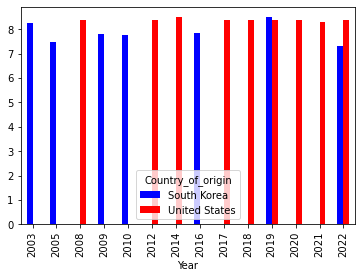

In [11]:
import matplotlib.pyplot as plt
%matplotlib inline

#If you are unfamilar with matplot, please refer to the Introduction to Common Python Libraries under tutorials
Average_Movie_Ratings = Top10_Both.groupby(['Year', 'Country_of_origin'])['Rating'].mean()
separated_by_country = Average_Movie_Ratings.unstack().plot(kind = 'bar', color = ['blue', 'red'])
